In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\asus\Downloads\Cynbit_Complete_Assessment_Rishikesh_Tiwari\sample_inquiries.csv")

print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

                                             inquiry             category
0  We need an AI chatbot to answer questions from...  AI Automation & LLM
1  Build an LLM agent that summarizes incoming cu...  AI Automation & LLM
2      Automate invoice extraction from PDFs with AI  AI Automation & LLM
3  We want a generative AI assistant for employee...  AI Automation & LLM
4  Create a retrieval augmented generation chatbo...  AI Automation & LLM
Dataset shape: (70, 2)
Columns: ['inquiry', 'category']


In [7]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [5]:
if os.path.exists("sample_inquiries.csv"):
    df = pd.read_csv("sample_inquiries.csv")
    print("Dataset loaded successfully!")
else:
    data = {
        "inquiry": [
            "I forgot my password",
            "I cannot log in to my account",
            "Please reset my password",
            "My account is locked",
            "I need help signing in",
            "My application is crashing",
            "The dashboard is not loading",
            "I receive an error while uploading",
            "The software is running slowly",
            "My application is not working",
            "I want pricing information",
            "Please send me a product quotation",
            "I need a product demonstration",
            "What plans do you offer?",
            "I want to purchase your service",
            "I was charged twice",
            "I need a copy of my invoice",
            "Please explain my payment",
            "I want a refund",
            "My bill contains an incorrect charge",
            "I want to automate business tasks using AI",
            "Can you build an AI chatbot?",
            "I need machine learning solutions",
            "Can AI automate customer support?",
            "I want an AI assistant for my business"
        ],
        "category": [
            "account_access", "account_access", "account_access",
            "account_access", "account_access",
            "technical_support", "technical_support",
            "technical_support", "technical_support", "technical_support",
            "sales", "sales", "sales", "sales", "sales",
            "billing", "billing", "billing", "billing", "billing",
            "ai_automation", "ai_automation", "ai_automation",
            "ai_automation", "ai_automation"
        ]
    }

    df = pd.DataFrame(data)
    print("Using demonstration dataset.")

print("Dataset shape:", df.shape)
display(df.head())

Using demonstration dataset.
Dataset shape: (25, 2)


,inquiry,category
0,I forgot my password,account_access
1,I cannot log in to my account,account_access
2,Please reset my password,account_access
3,My account is locked,account_access
4,I need help signing in,account_access


In [6]:
print("Column names:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())


TEXT_COLUMN = "inquiry"
LABEL_COLUMN = "category"

df = df[[TEXT_COLUMN, LABEL_COLUMN]].copy()
df.columns = ["inquiry", "category"]

df = df.dropna()
df["inquiry"] = df["inquiry"].astype(str).str.strip()
df["category"] = df["category"].astype(str).str.strip()

df = df[
    (df["inquiry"] != "") &
    (df["category"] != "")
]

df = df.drop_duplicates().reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)
print("\nCategory distribution:")
print(df["category"].value_counts())

Column names: ['inquiry', 'category']

Missing values:
inquiry     0
category    0
dtype: int64

Cleaned dataset shape: (25, 2)

Category distribution:
category
account_access       5
technical_support    5
sales                5
billing              5
ai_automation        5
Name: count, dtype: int64


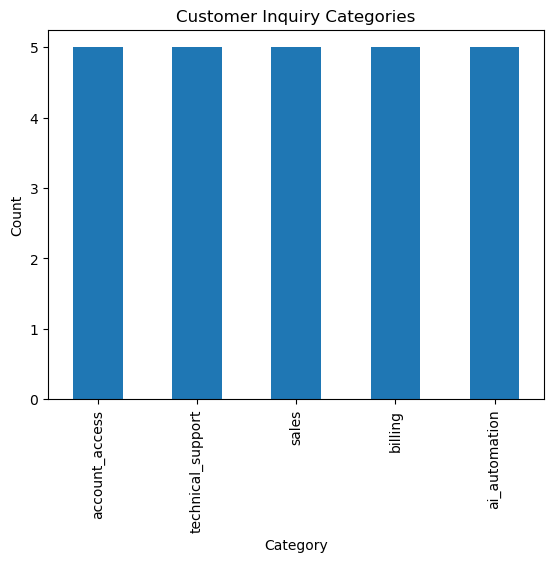

In [8]:
df["category"].value_counts().plot(kind="bar")

plt.title("Customer Inquiry Categories")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

In [9]:
X = df["inquiry"]
y = df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 18
Testing data: 7


In [10]:
vectorizer = TfidfVectorizer()

X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

print("Text converted into numerical data")

Text converted into numerical data


In [11]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [12]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 28.57 %
                   precision    recall  f1-score   support

   account_access       1.00      0.50      0.67         2
    ai_automation       0.00      0.00      0.00         1
          billing       0.00      0.00      0.00         1
            sales       0.00      0.00      0.00         2
technical_support       1.00      1.00      1.00         1

         accuracy                           0.29         7
        macro avg       0.40      0.30      0.33         7
     weighted avg       0.43      0.29      0.33         7



In [13]:
new_inquiry = ["I need an AI chatbot for my business"]

new_inquiry = vectorizer.transform(new_inquiry)

prediction = model.predict(new_inquiry)

print("Predicted Category:", prediction[0])

Predicted Category: ai_automation


In [14]:
import joblib

joblib.dump(model, "cynbit_model.pkl")
joblib.dump(vectorizer, "cynbit_vectorizer.pkl")

print("Model saved successfully!")

Model saved successfully!


In [15]:
inquiries = [
    "I forgot my password",
    "My application is crashing",
    "I need pricing information",
    "I want a refund",
    "I need AI automation"
]

inquiries_vectorized = vectorizer.transform(inquiries)
predictions = model.predict(inquiries_vectorized)

for inquiry, category in zip(inquiries, predictions):
    print("Inquiry:", inquiry)
    print("Category:", category)
    print("-" * 30)

Inquiry: I forgot my password
Category: account_access
------------------------------
Inquiry: My application is crashing
Category: technical_support
------------------------------
Inquiry: I need pricing information
Category: sales
------------------------------
Inquiry: I want a refund
Category: billing
------------------------------
Inquiry: I need AI automation
Category: ai_automation
------------------------------


In [17]:
import streamlit as st
import joblib


st.set_page_config(
    page_title="Cynbit AI Assistant",
    page_icon="🤖"
)


model = joblib.load("cynbit_model.pkl")
vectorizer = joblib.load("cynbit_vectorizer.pkl")

st.title("🤖 Cynbit AI Inquiry Classifier")

st.write(
    "Enter a customer inquiry to predict its category."
)


inquiry = st.text_area(
    "Customer Inquiry",
    placeholder="Example: I need an AI chatbot for my business"
)


if st.button("Predict Category"):

    if inquiry.strip() == "":
        st.warning("Please enter a customer inquiry.")

    else:
       
        inquiry_vector = vectorizer.transform([inquiry])

      
        prediction = model.predict(inquiry_vector)

        
        st.success("Predicted Category: " + prediction[0])

st.write("---")
st.caption("Cynbit AI/ML Engineer Intern Assessment | Proof of Concept")

2026-10-18 17:13:17.850 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-18 17:13:17.873 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-18 17:13:18.247 
  command:

    streamlit run C:\Users\asus\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-18 17:13:18.248 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-18 17:13:18.249 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-18 17:13:18.249 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-18 17:13:18.250 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runni

DeltaGenerator()

In [18]:
%pip install pandas scikit-learn joblib

In [20]:
import os

print("Model file exists:", os.path.exists("cynbit_model.pkl"))
print("Vectorizer file exists:", os.path.exists("cynbit_vectorizer.pkl"))

Model file exists: True
Vectorizer file exists: True


In [21]:
print(os.getcwd())

C:\Users\asus


In [24]:
import joblib
import os


joblib.dump(model, r"C:\Users\asus\cynbit_model.pkl")


joblib.dump(vectorizer, r"C:\Users\asus\cynbit_vectorizer.pkl")

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!


In [26]:
loaded_model = joblib.load(r"C:\Users\asus\cynbit_model.pkl")
loaded_vectorizer = joblib.load(r"C:\Users\asus\cynbit_vectorizer.pkl")

inquiry = ["I need an AI chatbot for my business"]

inquiry_numbers = loaded_vectorizer.transform(inquiry)
prediction = loaded_model.predict(inquiry_numbers)

print("Predicted category:", prediction[0])

Predicted category: ai_automation
